# Листок № 1. СЛАУ, матрицы, квадратичные формы


Метод Гаусса–Жордана, определитель, операции с матрицами, произведение Кронекера
и поиск минимального многочлена реализованы своими функциями.
`Fraction` из стандартной библиотеки обеспечивает точные рациональные вычисления.
NumPy используется для численного поиска комплексных собственных значений,
SymPy — для записи формул и проверки преобразований с радикалами,
Matplotlib — для двух требуемых рисунков. Нужны пакеты `numpy`, `sympy`, `matplotlib`.

## Вспомогательные функции


In [24]:
from fractions import Fraction
from itertools import combinations
from math import exp, log, log1p, fsum, sqrt, comb
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display

sp.init_printing(use_latex='mathjax')
def eye(n): return [[int(i == j) for j in range(n)] for i in range(n)]


def transpose(A):
    return [list(row) for row in zip(*A)]


def matmul(A, B):
    if len(A[0]) != len(B):
        raise ValueError("Несогласованные размеры матриц")
    columns = transpose(B)
    return [[sum(a * b for a, b in zip(row, col)) for col in columns] for row in A]


def matadd(A, B):
    return [[a + b for a, b in zip(ra, rb)] for ra, rb in zip(A, B)]


def rref(A, coefficient_columns=None):
    """Точная ступенчатая редукция; правые части можно исключить из поиска опор."""
    R = [[Fraction(x) for x in row] for row in A]
    rows, cols = len(R), len(R[0])
    limit = cols if coefficient_columns is None else coefficient_columns
    pivots, r = [], 0
    for c in range(limit):
        pivot = next((i for i in range(r, rows) if R[i][c]), None)
        if pivot is None:
            continue
        R[r], R[pivot] = R[pivot], R[r]
        value = R[r][c]
        R[r] = [x / value for x in R[r]]
        for i in range(rows):
            if i != r and R[i][c]:
                factor = R[i][c]
                R[i] = [x - factor * y for x, y in zip(R[i], R[r])]
        pivots.append(c)
        r += 1
        if r == rows:
            break
    return R, pivots


def solve_affine(A, b):
    """Возвращает rref(A|b), частное решение и базис однородных решений."""
    n = len(A[0])
    R, pivots = rref([list(row) + [rhs] for row, rhs in zip(A, b)], n)
    if any(not any(row[:n]) and row[n] for row in R):
        raise ValueError("Система несовместна")
    free = [j for j in range(n) if j not in pivots]
    particular = [Fraction(0) for _ in range(n)]
    for i, p in enumerate(pivots):
        particular[p] = R[i][n]
    basis = []
    for f in free:
        vector = [Fraction(0) for _ in range(n)]
        vector[f] = Fraction(1)
        for i, p in enumerate(pivots):
            vector[p] = -R[i][f]
        basis.append(vector)
    return R, particular, basis


def show_solution(A, b, names):
    R, p, basis = solve_affine(A, b)
    params = sp.symbols(f't1:{len(basis) + 1}')
    result = sp.Matrix(p)
    for t, v in zip(params, basis):
        result += t * sp.Matrix(v)
    print("rref(A|b):")
    display(sp.Matrix(R))
    for name, expression in zip(names, result):
        display(sp.Eq(sp.Symbol(name), expression))
    print("Параметры произвольные действительные:", params)
    assert sp.Matrix(A) * result == sp.Matrix(b)
    return result


def det_bareiss(A):
    """Определитель целочисленной квадратной матрицы, без float."""
    n = len(A)
    if n == 0:
        return 1
    M = [list(row) for row in A]
    sign, previous = 1, 1
    for k in range(n - 1):
        p = next((i for i in range(k, n) if M[i][k]), None)
        if p is None:
            return 0
        if p != k:
            M[k], M[p] = M[p], M[k]
            sign = -sign
        pivot = M[k][k]
        for i in range(k + 1, n):
            for j in range(k + 1, n):
                M[i][j] = (pivot * M[i][j] - M[i][k] * M[k][j]) // previous
            M[i][k] = 0
        previous = pivot
    return sign * M[-1][-1]


print("Вспомогательные функции готовы.")

Вспомогательные функции готовы.


## 1.1. Общее решение СЛАУ

**Условие.** Решить систему
$$\begin{cases}x_1+5x_2-2x_3=-7,\\-3x_1+x_2+9x_3-5x_4=9,\\
4x_1-8x_2-x_3+7x_4=0.\end{cases}$$

**Теория.** Преобразования строк расширенной матрицы сохраняют множество решений.
Переменные без ведущих элементов свободны. При ранге 3 и четырёх неизвестных
получаем один параметр $t=x_4$:
$$x=\left(-\frac{11+8t}{7},\frac{-6+2t}{7},\frac{4+t}{7},t\right),\quad t\in\mathbb R.$$

In [25]:
A1 = [[1, 5, -2, 0], [-3, 1, 9, -5], [4, -8, -1, 7]]
b1 = [-7, 9, 0]
solution1 = show_solution(A1, b1, ['x_1', 'x_2', 'x_3', 'x_4'])

rref(A|b):


⎡1  0  0  8/7   -11/7⎤
⎢                    ⎥
⎢0  1  0  -2/7  -6/7 ⎥
⎢                    ⎥
⎣0  0  1  -1/7   4/7 ⎦

       8⋅t₁   11
x₁ = - ──── - ──
        7     7 

     2⋅t₁   6
x₂ = ──── - ─
      7     7

     t₁   4
x₃ = ── + ─
     7    7

x₄ = t₁

Параметры произвольные действительные: (t1,)


## 1.2. RREF и общее решение

**Условие.** Найти rref расширенной матрицы и решить систему
$$\begin{cases}5x_1-x_2+5x_3+9x_4-2x_5=-3,\\
3x_1+6x_3+9x_4-x_5=4,\\2x_1+4x_3+6x_4-x_5=0.\end{cases}$$

**Теория.** В приведённой ступенчатой форме каждый ведущий столбец содержит
единственную единицу. Здесь свободны $x_3=s$ и $x_4=t$:
$$x=(4-2s-3t,\;7-5s-6t,\;s,\;t,\;8),\qquad s,t\in\mathbb R.$$

In [26]:
A2 = [[5, -1, 5, 9, -2], [3, 0, 6, 9, -1], [2, 0, 4, 6, -1]]
b2 = [-3, 4, 0]
solution2 = show_solution(A2, b2, ['x_1', 'x_2', 'x_3', 'x_4', 'x_5'])

rref(A|b):


⎡1  0  2  3  0  4⎤
⎢                ⎥
⎢0  1  5  6  0  7⎥
⎢                ⎥
⎣0  0  0  0  1  8⎦

x₁ = -2⋅t₁ - 3⋅t₂ + 4

x₂ = -5⋅t₁ - 6⋅t₂ + 7

x₃ = t₁

x₄ = t₂

x₅ = 8

Параметры произвольные действительные: (t1, t2)


## 1.3. Зависимость $y=a+bx$

**Условие.** Для решений системы
$$\begin{cases}32x+97y+90z+48u=47,\\35x+84y+91z+54u=40,\\
17x+18y+21z+13u=37\end{cases}$$
объяснить зависимость $y=a+bx$ и найти $a,b$.

**Теория.** Перенесём слагаемые с $x$ вправо: $C(y,z,u)^T=d-xv$.
Если $\det C\ne0$, то $(y,z,u)^T=C^{-1}d-xC^{-1}v$.
Следовательно, $y$ линейно зависит от $x$, причём $x$ может быть любым действительным числом.
Две правые части удобно преобразовывать одновременно, не вычисляя обратную матрицу.

In [27]:
C3 = [[97, 90, 48], [84, 91, 54], [18, 21, 13]]
d3, v3 = [47, 40, 37], [32, 35, 17]
R3, pivots3 = rref([row + [d, -v] for row, d, v in zip(C3, d3, v3)], 3)
assert pivots3 == [0, 1, 2]
a3, b3 = R3[0][3:]
print("det C =", det_bareiss(C3))
print(f"Ответ: a = {a3}, b = {b3}; y = {a3} - {abs(b3)}x")
x = sp.Symbol('x', real=True)
Y3 = sp.Matrix([row[3] + x * row[4] for row in R3])
assert sp.simplify(sp.Matrix(C3) * Y3 - sp.Matrix(d3) + x * sp.Matrix(v3)) == sp.zeros(3, 1)

det C = 1
Ответ: a = 14027, b = -4262; y = 14027 - 4262x


## 1.4. Произведение и сумма матриц

**Условие.** Вычислить $AB+C$, где матрицы из листка заданы в следующей ячейке.

**Теория.** Если $A$ имеет размер $4\times3$, а $B$ — $3\times4$, то
$AB$ имеет размер $4\times4$ и $(AB)_{ij}=\sum_{k=1}^{3}a_{ik}b_{kj}$.
Складываем матрицы поэлементно. Используем собственные `matmul` и `matadd`.

In [28]:
A4 = [[3, 0, 2], [0, 1, 3], [2, 2, 0], [0, 1, 0]]
B4 = [[1, 2, -1, 2], [-2, -1, 1, 2], [2, 1, 1, 2]]
C4 = [[0, -4, 6, 1], [2, 2, -5, -2], [2, -2, 6, 4], [1, 3, 0, 1]]
result4 = matadd(matmul(A4, B4), C4)
print("AB + C =")
display(sp.Matrix(result4))

AB + C =


⎡7   4  5   11⎤
⎢             ⎥
⎢6   4  -1  6 ⎥
⎢             ⎥
⎢0   0  6   12⎥
⎢             ⎥
⎣-1  2  1   3 ⎦

## 1.5. Определители порядка $n$

**Условие.** Найти определители при $a_{ij}=\min(i,j)$, $\max(i,j)$ и $|i-j|$,
где $i,j=1,\ldots,n$.

**Теория и вывод.** Пусть $D$ — матрица разностей: $D_{ii}=1$, $D_{i,i-1}=-1$,
остальные элементы нулевые. Тогда $\det D=1$, поэтому $\det(DAD^T)=\det A$.
Такое преобразование вычитает соседние строки, затем соседние столбцы.

а) Для $\min(i,j)$ получаем $DAD^T=I$, поэтому **$\det A=1$**.

б) Для $\max(i,j)$ получаем
$\begin{pmatrix}1&\mathbf1^T\\\mathbf1&-I_{n-1}\end{pmatrix}$.
Прибавление нижних строк к первой обнуляет её элементы кроме первого, равного $n$.
Значит, **$\det A=(-1)^{n-1}n$**.

в) Для $|i-j|$ получаем
$\begin{pmatrix}0&\mathbf1^T\\\mathbf1&-2I_{n-1}\end{pmatrix}$.
Прибавим к первой строке половину суммы остальных строк: первый элемент станет $(n-1)/2$.
Поэтому **$\det A=(-1)^{n-1}(n-1)2^{n-2}$ при $n\ge2$**;
при $n=1$ определитель равен **0**.
Вычисление по формулам не требует создания матрицы.

In [29]:
def structured_determinants(n):
    if not isinstance(n, int) or n < 1:
        raise ValueError("n должно быть положительным целым")
    return (1, (-1)**(n - 1) * n,
            0 if n == 1 else (-1)**(n - 1) * (n - 1) * 2**(n - 2))


print(" n | det min | det max | det |i-j|")
for n in range(1, 9):
    formulas = structured_determinants(n)
    actual = tuple(det_bareiss([[f(i, j) for j in range(1, n + 1)]
                               for i in range(1, n + 1)])
                   for f in (min, max, lambda i, j: abs(i - j)))
    assert actual == formulas
    print(f"{n:2} | {formulas[0]:7} | {formulas[1]:7} | {formulas[2]:9}")

 n | det min | det max | det |i-j|
 1 |       1 |       1 |         0
 2 |       1 |      -2 |        -1
 3 |       1 |       3 |         4
 4 |       1 |      -4 |       -12
 5 |       1 |       5 |        32
 6 |       1 |      -6 |       -80
 7 |       1 |       7 |       192
 8 |       1 |      -8 |      -448


## 1.6. Максимальный определитель шестого порядка

**Условие.** Найти наибольший определитель матрицы $6\times6$ с элементами $-1,0,1$.

**Теория и сокращение перебора.** Определитель линеен по каждому элементу при фиксированных
остальных. Его модуль на отрезке $[-1,1]$ достигает максимума на одном из концов.
Последовательно заменяя нули, получаем матрицу из $\{-1,1\}$ с не меньшим модулем определителя.
Знак можно изменить перестановкой двух строк, поэтому максимальный определитель равен
максимальному модулю.

Умножением строк и столбцов на $-1$ нормируем первую строку и первый столбец к единицам.
Вычтем первую строку из остальных. Нижний правый блок станет $-2C$, где
$C\in\{0,1\}^{5\times5}$, и $|\det A|=2^5|\det C|$.
У невырожденной $C$ все строки ненулевые и различны. Перестановка строк не меняет модуль,
поэтому достаточно перебрать **$\binom{31}{5}=169\,911$** наборов строк вместо $3^{36}$ матриц.

Полный точный перебор ниже даёт $\max|\det C|=5$, значит **ответ: $160$**.
Программа также строит матрицу, на которой максимум достигается.

In [30]:
binary_rows = [tuple((mask >> j) & 1 for j in range(5)) for mask in range(1, 32)]
best_det, best_rows, checked = -1, None, 0
for rows in combinations(binary_rows, 5):
    value = abs(det_bareiss(rows))
    checked += 1
    if value > best_det:
        best_det, best_rows = value, rows

A6 = [[1] * 6] + [[1] + [1 - 2 * bit for bit in row] for row in best_rows]
if det_bareiss(A6) < 0:
    A6[0], A6[1] = A6[1], A6[0]
assert checked == comb(31, 5) and best_det == 5 and det_bareiss(A6) == 160
print(f"Проверено наборов строк: {checked}; max |det C| = {best_det}")
print("Матрица с определителем 160:")
display(sp.Matrix(A6))
print("Ответ:", det_bareiss(A6))

Проверено наборов строк: 169911; max |det C| = 5
Матрица с определителем 160:


⎡1  -1  -1  1   1   1 ⎤
⎢                     ⎥
⎢1  1   1   1   1   1 ⎥
⎢                     ⎥
⎢1  -1  1   -1  1   1 ⎥
⎢                     ⎥
⎢1  1   -1  -1  -1  1 ⎥
⎢                     ⎥
⎢1  1   -1  -1  1   -1⎥
⎢                     ⎥
⎣1  -1  1   1   -1  -1⎦

Ответ: 160


## 1.7. Определитель и след обратной матрицы размера 80 000

**Условие.** Диагональ — арифметическая прогрессия от $0.99$ до $1.01$;
вне диагонали ненулевые только $a_{12}=0.57$, $a_{21}=0.03$.

**Теория.** Матрица блочно-диагональна: один блок $2\times2$ и скалярные блоки $d_i$.
При $d_i=0.99+0.02(i-1)/(n-1)$ и $\Delta=d_1d_2-0.57\cdot0.03$ имеем
$$\det A=\Delta\prod_{i=3}^n d_i,\qquad
\operatorname{tr}(A^{-1})=\frac{d_1+d_2}{\Delta}+\sum_{i=3}^n\frac1{d_i}.$$
Произведение вычисляем через сумму логарифмов. Время $O(n)$, дополнительная память $O(1)$:
плотная матрица и её обратная не нужны.

In [31]:
n7 = 80000


def diagonal7(i):
    return 0.99 + 0.02 * (i - 1) / (n7 - 1)


d1, d2 = diagonal7(1), diagonal7(2)
delta7 = d1 * d2 - 0.57 * 0.03
det7 = exp(log(delta7) + fsum(log(diagonal7(i)) for i in range(3, n7 + 1)))
trace7 = (d1 + d2) / delta7 + fsum(1 / diagonal7(i) for i in range(3, n7 + 1))
print(f"det A = {det7:.9f} ≈ {det7:.3f}")
print(f"tr(A⁻¹) = {trace7:.9f} ≈ {trace7:.3f}")
assert round(det7, 3) == 0.259 and round(trace7, 3) == 80002.703

det A = 0.258979114 ≈ 0.259
tr(A⁻¹) = 80002.702766086 ≈ 80002.703


## 1.8. Обратная матрица размера 43 000

**Условие.** Диагональ — геометрическая прогрессия от $1$ до $1.07$,
первая строка — арифметическая прогрессия от $1$ до $1.10$;
остальные внедиагональные элементы нулевые. Найти $B=A^{-1}$, её минимум и сумму элементов.

**Теория.** Обозначим $q=1.07^{1/(n-1)}$, $d_j=q^{j-1}$,
$r_j=1+0.10(j-1)/(n-1)$. Из $AB=I$ следует полное описание обратной матрицы:
$$b_{ij}=\begin{cases}
1,&i=j=1,\\
d_i^{-1},&i=j\ge2,\\
-r_j/d_j,&i=1,\ j\ge2,\\
0,&\text{иначе}.
\end{cases}$$
Следовательно,
$$\sum_{i,j}b_{ij}=1+\sum_{j=2}^n\frac{1-r_j}{d_j}.$$
Функция $(1+0.1t)e^{-t\ln1.07}$ возрастает на $[0,1]$, так как
$0.1/(1+0.1t)>\ln1.07$. Поэтому минимум $B$ достигается в $b_{1n}=-1.10/1.07$.
Храним обратную матрицу как функцию доступа к элементу; сумма требует $O(n)$ времени и $O(1)$ памяти.

In [32]:
def inverse8_entry(i, j, n=43000):
    """Элемент B с нумерацией строк/столбцов от 1."""
    if not (1 <= i <= n and 1 <= j <= n) or n < 2:
        raise ValueError("Индексы вне матрицы")
    t = (j - 1) / (n - 1)
    inv_d = exp(-log1p(0.07) * t)
    if i == j:
        return inv_d
    if i == 1:
        return -(1 + 0.10 * t) * inv_d
    return 0.0


n8 = 43000
min8 = inverse8_entry(1, n8)
sum8 = 1 + fsum(-0.10 * (j - 1) / (n8 - 1)
                * exp(-log1p(0.07) * (j - 1) / (n8 - 1))
                for j in range(2, n8 + 1))
print(f"Минимум B = {min8:.9f} ≈ {min8:.3f}")
print(f"Сумма элементов B = {sum8:.9f} ≈ {sum8:.1f}")
# Проверка той же формулы на небольшом размере.
m8 = 6
A8_small = [[(1 + 0.1 * j / (m8 - 1)) if i == 0 else
             (exp(log1p(0.07) * i / (m8 - 1)) if i == j else 0)
             for j in range(m8)] for i in range(m8)]
B8_small = [[inverse8_entry(i + 1, j + 1, m8) for j in range(m8)] for i in range(m8)]
assert np.allclose(matmul(A8_small, B8_small), eye(m8))

Минимум B = -1.028037383 ≈ -1.028
Сумма элементов B = -2054.438267009 ≈ -2054.4


## 1.9. Матричная геометрическая прогрессия

**Условие.** $A=0.057\begin{pmatrix}7&14\\9&1\end{pmatrix}$,
$S_{m,n}=\sum_{i=m}^{n}A^i$, $B_m=(I-A)^{-1}A^m$.
Найти максимальные элементы $S_{4,70}$ и $B_4$, а также наименьшее $k$, для которого
при любом $n>k$ максимальный элемент $S_{k,n}$ меньше $0.0002$.

**Теория.** Собственные значения $A$ равны $0.057(4\pm3\sqrt{15})$,
их модули меньше 1. Поэтому $B_k=\sum_{i=k}^{\infty}A^i$.
Все элементы $A$ положительны, конечные суммы строго возрастают к $B_k$.
Условие для всех конечных $n>k$ равносильно $\max B_k\le0.0002$
(равенство допустимо, поскольку конечная сумма строго меньше предела).
Матрицы хвостов убывают поэлементно: $B_{k+1}=B_k-A^k$.
Проверяем соседние хвосты, чтобы подтвердить минимальность $k$.

In [33]:
def inverse2(A):
    a, b = A[0]
    c, d = A[1]
    determinant = a * d - b * c
    if determinant == 0:
        raise ValueError("Вырожденная матрица")
    return [[d / determinant, -b / determinant], [-c / determinant, a / determinant]]


def max_entry(A):
    return max(max(row) for row in A)


A9 = [[0.057 * 7, 0.057 * 14], [0.057 * 9, 0.057]]
I_minus_A9 = [[int(i == j) - A9[i][j] for j in range(2)] for i in range(2)]
inverse9 = inverse2(I_minus_A9)
power9, sum9, power4 = eye(2), [[0.0] * 2 for _ in range(2)], None
for i in range(1, 71):
    power9 = matmul(power9, A9)
    if i == 4:
        power4 = power9
    if i >= 4:
        sum9 = matadd(sum9, power9)
tail4 = matmul(inverse9, power4)
print(f"max S₄,₇₀ = {max_entry(sum9):.6f}")
print(f"max B₄ = {max_entry(tail4):.6f}")

epsilon9 = 0.0002
k9, tail9 = 0, inverse9
previous9 = None
while max_entry(tail9) > epsilon9:
    previous9 = max_entry(tail9)
    tail9 = matmul(tail9, A9)
    k9 += 1
print(f"max B_{k9 - 1} = {previous9:.10f} > {epsilon9}")
print(f"max B_{k9} = {max_entry(tail9):.10f} < {epsilon9}")
print("Наименьшее k =", k9)
assert k9 == 89 and previous9 > epsilon9 > max_entry(tail9)

max S₄,₇₀ = 3.609679
max B₄ = 3.611175
max B_88 = 0.0002073877 > 0.0002
max B_89 = 0.0001846331 < 0.0002
Наименьшее k = 89


## 1.10. Определитель как многочлен

**Условие.** Для $M=\begin{pmatrix}7&5&5&x\\2&2&6&9\\3&x&8&0\\3&1&1&0\end{pmatrix}$
записать $\det M=ax^2+bx+c$ и найти $a,b$.

**Теория.** Переменная встречается в двух элементах, поэтому степень определителя не выше двух.
Можно восстановить многочлен по трём значениям без символьного вычисления определителя:
$$c=p(0),\quad b=\frac{p(1)-p(-1)}2,\quad
a=\frac{p(1)+p(-1)-2p(0)}2.$$

In [34]:
def matrix10(x):
    return [[7, 5, 5, x], [2, 2, 6, 9], [3, x, 8, 0], [3, 1, 1, 0]]


p0, p1, pm1 = (det_bareiss(matrix10(t)) for t in (0, 1, -1))
c10 = p0
b10 = Fraction(p1 - pm1, 2)
a10 = Fraction(p1 + pm1 - 2 * p0, 2)
x10 = sp.Symbol('x')
display(sp.Eq(sp.Symbol('det_M'), a10 * x10**2 + b10 * x10 + c10))
print(f"Ответ: a = {a10}, b = {b10}")
assert all(det_bareiss(matrix10(t)) == a10 * t*t + b10 * t + c10 for t in (2, -3, 7))

            2              
det_M = 16⋅x  - 116⋅x + 576

Ответ: a = 16, b = -116


## 1.11. Биномиальные коэффициенты по модулю 2

**Условие.** Изобразить матрицу $100\times100$ с элементами $\binom{i}{j}\bmod2$,
где $i,j=1,\ldots,100$; выше диагонали стоят нули. Единицы — синие, нули — жёлтые.

**Теория.** В арифметике по модулю 2 имеем $(1+t)^{2^r}=1+t^{2^r}$.
Разложив $i$ по двоичным разрядам, получаем: коэффициент при $t^j$ равен 1 тогда и только тогда,
когда каждый единичный бит $j$ присутствует в $i$. Это проверка **`(i & j) == j`**.
Она не требует вычисления факториалов или больших биномиальных коэффициентов.
Индексация начинается с 1, как в листке: столбец $\binom{i}{0}$ не включён.

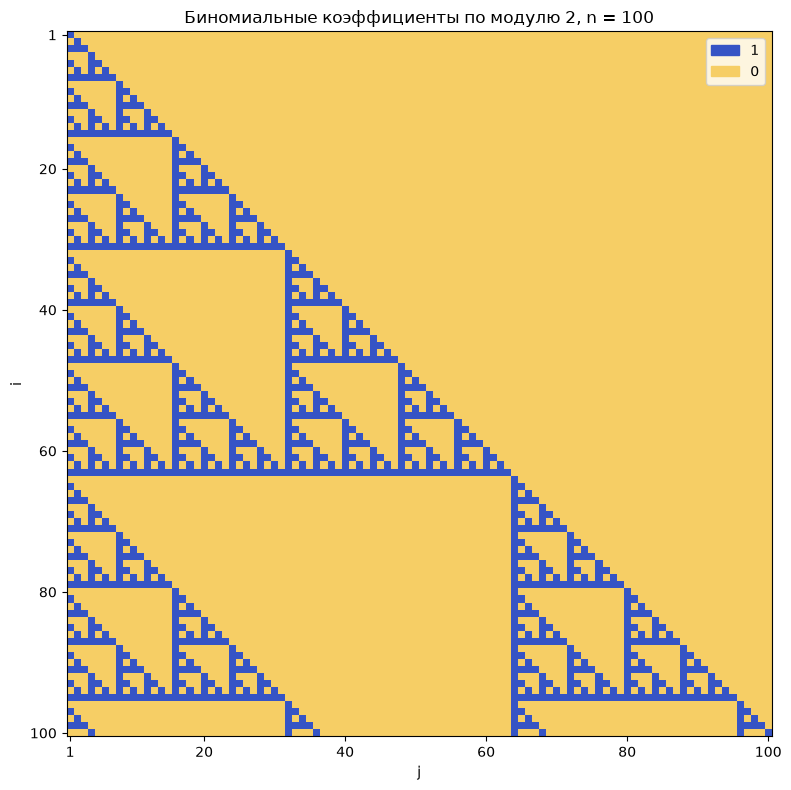

In [35]:
def binomial_mod2_matrix(n):
    return [[int((i & j) == j) for j in range(1, n + 1)] for i in range(1, n + 1)]


assert binomial_mod2_matrix(3) == [[1, 0, 0], [0, 1, 0], [1, 1, 1]]
assert all(int((i & j) == j) == comb(i, j) % 2 for i in range(1, 20) for j in range(i + 1))
P11 = binomial_mod2_matrix(100)
fig11, ax11 = plt.subplots(figsize=(8, 8))
ax11.imshow(P11, cmap=ListedColormap(['#F6CE65', '#3654C5']),
            vmin=0, vmax=1, interpolation='nearest', extent=(0.5, 100.5, 100.5, 0.5))
ax11.set(title='Биномиальные коэффициенты по модулю 2, n = 100', xlabel='j', ylabel='i',
         xticks=[1, 20, 40, 60, 80, 100], yticks=[1, 20, 40, 60, 80, 100])
ax11.legend(handles=[Patch(color='#3654C5', label='1'), Patch(color='#F6CE65', label='0')],
            loc='upper right')
fig11.tight_layout()
plt.show()

## 1.12. Матрицы Адамара

**Условие.** Выписать $H_1,H_2,H_4$, проверить $H_4=H_2\otimes H_2$,
обосновать $H_{2^k}=H_2\otimes H_{2^{k-1}}$ и изобразить $H_{64}$.

**Теория.** Используем построение Сильвестра:
$$H_1=(1),\quad H_2=\begin{pmatrix}1&1\\1&-1\end{pmatrix},\quad
H_{2m}=\begin{pmatrix}H_m&H_m\\H_m&-H_m\end{pmatrix}=H_2\otimes H_m.$$
Произведение Кронекера заменяет элемент $a_{ij}$ целым блоком $a_{ij}B$.
Если $H_mH_m^T=mI_m$, то блочное умножение даёт
$$H_{2m}H_{2m}^T=\begin{pmatrix}2mI_m&0\\0&2mI_m\end{pmatrix}.$$
Это доказывает требуемую формулу и свойство Адамара по индукции.
Формула относится к этому согласованному выбору матриц, а не к любой перестановке их строк.

В иллюстрации листка строки переставлены. Для сходного рисунка упорядочим их по числу смен знака;
перестановка сохраняет $HH^T=64I$. Положительные элементы оранжевые, отрицательные синие.

H_1 =


[1]

H_2 =


⎡1  1 ⎤
⎢     ⎥
⎣1  -1⎦

H_4 =


⎡1  1   1   1 ⎤
⎢             ⎥
⎢1  -1  1   -1⎥
⎢             ⎥
⎢1  1   -1  -1⎥
⎢             ⎥
⎣1  -1  -1  1 ⎦

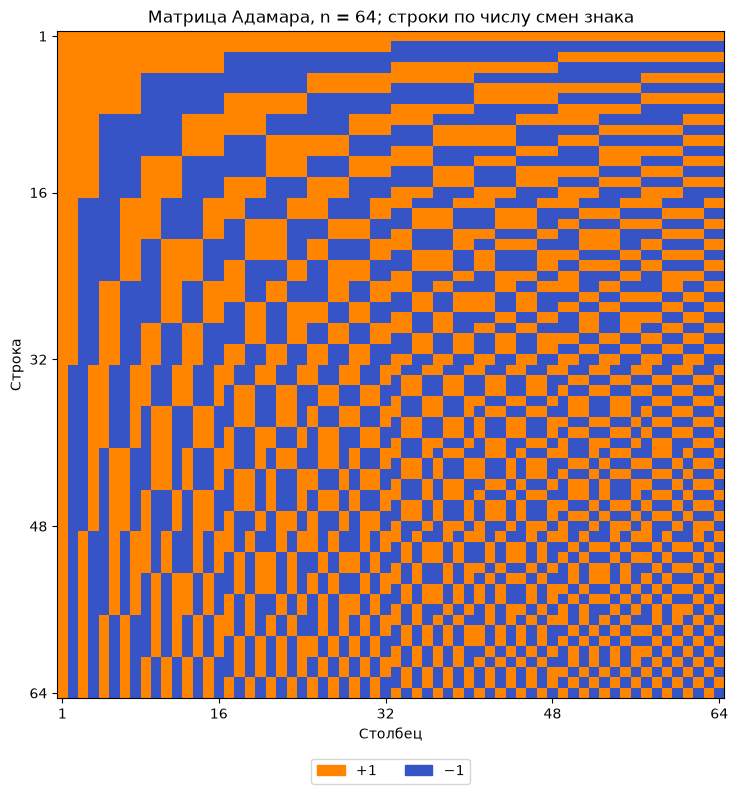

In [36]:
def kron(A, B):
    return [[a * b for a in row_a for b in row_b] for row_a in A for row_b in B]


def hadamard(n):
    if n < 1 or n & (n - 1):
        raise ValueError("Размер должен быть степенью двойки")
    H = [[1]]
    while len(H) < n:
        H = kron([[1, 1], [1, -1]], H)
    return H


for size in (1, 2, 4):
    print(f"H_{size} =")
    display(sp.Matrix(hadamard(size)))
assert hadamard(4) == kron(hadamard(2), hadamard(2))
H64 = hadamard(64)
assert matmul(H64, transpose(H64)) == [[64 * x for x in row] for row in eye(64)]
H64_plot = sorted(H64, key=lambda row: sum(a != b for a, b in zip(row, row[1:])))
fig12, ax12 = plt.subplots(figsize=(8, 8))
ax12.imshow(H64_plot, cmap=ListedColormap(['#3654C5', '#FF8500']),
            vmin=-1, vmax=1, interpolation='nearest', extent=(0.5, 64.5, 64.5, 0.5))
ax12.set(title='Матрица Адамара, n = 64; строки по числу смен знака', xlabel='Столбец',
         ylabel='Строка', xticks=[1, 16, 32, 48, 64], yticks=[1, 16, 32, 48, 64])
ax12.legend(handles=[Patch(color='#FF8500', label='+1'), Patch(color='#3654C5', label='−1')],
            loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
fig12.tight_layout()
plt.show()

## 1.13. Комплексное собственное значение и собственный вектор

**Условие.** Для $A=\begin{pmatrix}14&10&21\\12&15&26\\18&11&27\end{pmatrix}$
найти собственное значение $Z$ с наибольшей мнимой частью и собственный вектор
$X=(1,U,V)^T$. Указать $\operatorname{Im}Z$ и $\operatorname{Re}U$.

**Теория.** Собственные значения удовлетворяют $\det(A-ZI)=0$, а собственные векторы —
$(A-ZI)X=0$. Если первая координата найденного вектора ненулевая, делим весь вектор на неё.
Для общего несимметричного оператора удобен численный алгоритм `numpy.linalg.eig`:
самостоятельная реализация устойчивого поиска комплексных корней здесь усложнила бы решение.
Точность проверяем невязкой $\|AX-ZX\|_\infty$.

In [37]:
A13 = np.array([[14, 10, 21], [12, 15, 26], [18, 11, 27]], dtype=float)
eigenvalues13, eigenvectors13 = np.linalg.eig(A13)
index13 = np.argmax(eigenvalues13.imag)
Z13 = eigenvalues13[index13]
X13 = eigenvectors13[:, index13] / eigenvectors13[0, index13]
U13, V13 = X13[1:]
print("Собственные значения:", eigenvalues13)
print(f"Z = {Z13:.10f}")
print(f"X = (1, {U13:.10f}, {V13:.10f})")
print(f"Ответ: Im Z = {Z13.imag:.9f}; Re U = {U13.real:.9f}")
residual13 = np.max(np.abs(A13 @ X13 - Z13 * X13))
print(f"Невязка: {residual13:.2e}")
assert residual13 < 1e-10

Собственные значения: [52.06231934+0.j          1.96884033+0.34478935j  1.96884033-0.34478935j]
Z = 1.9688403308+0.3447893484j
X = (1, 3.7478197294+1.3308467741j, -2.3575884268-0.6173180187j)
Ответ: Im Z = 0.344789348; Re U = 3.747819729
Невязка: 1.72e-14


## 1.14. Минимальный многочлен

**Условие.** Найти минимальный многочлен матрицы $7\times7$, заданной ниже.

**Теория.** Минимальный многочлен — приведённый многочлен наименьшей степени,
для которого $m(A)=0$. Последовательно ищем первую линейную зависимость
$$A^d+c_{d-1}A^{d-1}+\cdots+c_1A+c_0I=0.$$
Каждую матрицу разворачиваем в столбец длины 49 и решаем СЛАУ относительно $c_i$
собственным методом Гаусса–Жордана в точных дробях.
Первая совместная система даёт минимальную степень: для всех меньших степеней
зависимость отсутствует. По теореме Кэли–Гамильтона степень не превышает 7.

In [38]:
A14 = [
    [-3, 7, -6, -1, 8, -3, -2],
    [1, -5, 8, -3, -5, 4, -5],
    [1, 3, -4, 6, -2, 0, 8],
    [-1, 11, -12, 9, 3, -3, 9],
    [-3, 11, -12, 5, 8, -4, 6],
    [-3, 2, 1, -4, 4, 1, -7],
    [1, -5, 6, -2, -4, 3, -2],
]


def flatten(A):
    return [value for row in A for value in row]


def minimal_polynomial_coefficients(A):
    """Коэффициенты в порядке c_0, ..., c_d; c_d = 1."""
    n = len(A)
    powers = [eye(n)]
    ranks = []
    for degree in range(1, n + 1):
        powers.append(matmul(powers[-1], A))
        columns = [flatten(P) for P in powers[:-1]]
        coefficient_matrix = transpose(columns)
        target = [-v for v in flatten(powers[-1])]
        R, pivots = rref([row + [b] for row, b in zip(coefficient_matrix, target)], degree)
        rank = len(pivots)
        inconsistent = any(not any(row[:degree]) and row[degree] for row in R)
        ranks.append((degree, rank, rank + int(inconsistent)))
        if not inconsistent:
            coefficients = [Fraction(0)] * degree
            for i, pivot in enumerate(pivots):
                coefficients[pivot] = R[i][degree]
            return coefficients + [Fraction(1)], powers, ranks
    raise ArithmeticError("Зависимость не найдена")


coefficients14, powers14, ranks14 = minimal_polynomial_coefficients(A14)
t14 = sp.Symbol('t')
polynomial14 = sum(sp.Rational(c) * t14**i for i, c in enumerate(coefficients14))
print("Матрица A:")
display(sp.Matrix(A14))
print("Степень | ранг коэффициентов | ранг расширенной матрицы")
for degree, rank, augmented_rank in ranks14:
    print(f"{degree:^7} | {rank:^18} | {augmented_rank:^24}")
print("Минимальный многочлен:")
display(sp.Eq(sp.Symbol('m_A'), sp.factor(polynomial14)))
display(sp.expand(polynomial14))
zero14 = [[sum(c * P[i][j] for c, P in zip(coefficients14, powers14))
           for j in range(7)] for i in range(7)]
assert zero14 == [[0] * 7 for _ in range(7)]
print("Проверено точно: m(A) = 0; системы для меньших степеней несовместны.")

Матрица A:


⎡-3  7   -6   -1  8   -3  -2⎤
⎢                           ⎥
⎢1   -5   8   -3  -5  4   -5⎥
⎢                           ⎥
⎢1   3   -4   6   -2  0   8 ⎥
⎢                           ⎥
⎢-1  11  -12  9   3   -3  9 ⎥
⎢                           ⎥
⎢-3  11  -12  5   8   -4  6 ⎥
⎢                           ⎥
⎢-3  2    1   -4  4   1   -7⎥
⎢                           ⎥
⎣1   -5   6   -2  -4  3   -2⎦

Степень | ранг коэффициентов | ранг расширенной матрицы
   1    |         1          |            2            
   2    |         2          |            3            
   3    |         3          |            4            
   4    |         4          |            5            
   5    |         5          |            5            
Минимальный многочлен:


       3        2
m_A = t ⋅(t - 1) 

 5      4    3
t  - 2⋅t  + t 

Проверено точно: m(A) = 0; системы для меньших степеней несовместны.


## 1.15. Собственный ортонормированный базис

**Условие.** Найти собственный ортонормированный базис и матрицу оператора
для $A=\begin{pmatrix}17&-8&4\\-8&17&-4\\4&-4&11\end{pmatrix}$.

**Теория.** Вещественная симметричная матрица имеет ортонормированный собственный базис.
Здесь $A=9I+2vv^T$, где $v=(2,-2,1)^T$ и $v^Tv=9$.
Поэтому $Av=27v$, а на плоскости $v^\perp$ оператор равен умножению на 9.
Выберем в этой плоскости два взаимно перпендикулярных единичных вектора:
$$e'_1=\frac{(1,1,0)^T}{\sqrt2},\qquad
e'_2=\frac{(1,-1,-4)^T}{3\sqrt2},\qquad
e'_3=\frac{(2,-2,1)^T}{3}.$$
Если столбцы $P$ — эти векторы, то $P^TP=I$ и
**$P^TAP=\operatorname{diag}(9,9,27)$**. Координаты связаны равенством $x=Py$.

In [39]:
A15 = sp.Matrix([[17, -8, 4], [-8, 17, -4], [4, -4, 11]])
P15 = sp.Matrix.hstack(sp.Matrix([1, 1, 0]) / sp.sqrt(2),
                      sp.Matrix([1, -1, -4]) / (3 * sp.sqrt(2)),
                      sp.Matrix([2, -2, 1]) / 3)
D15 = sp.simplify(P15.T * A15 * P15)
print("Ортонормированный базис — столбцы P:")
display(P15)
print("Матрица оператора в новом базисе:")
display(D15)
assert sp.simplify(P15.T * P15) == sp.eye(3)
assert D15 == sp.diag(9, 9, 27)
assert sp.simplify(A15 * P15 - P15 * D15) == sp.zeros(3)

Ортонормированный базис — столбцы P:


⎡√2    √2        ⎤
⎢──    ──    2/3 ⎥
⎢2     6         ⎥
⎢                ⎥
⎢√2   -√2        ⎥
⎢──   ────   -2/3⎥
⎢2     6         ⎥
⎢                ⎥
⎢    -2⋅√2       ⎥
⎢0   ──────  1/3 ⎥
⎣      3         ⎦

Матрица оператора в новом базисе:


⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦

## 1.16. Главные оси квадратичной формы

**Условие.** Найти ортогональное преобразование для
$$f=3x_1^2+8x_1x_2-3x_2^2+4x_3^2-4x_3x_4+x_4^2.$$

**Теория.** В записи $f=x^TAx$ коэффициент смешанного произведения $x_ix_j$
равен $2a_{ij}$. Матрица состоит из двух блоков $2\times2$:
$\begin{pmatrix}3&4\\4&-3\end{pmatrix}$ и $\begin{pmatrix}4&-2\\-2&1\end{pmatrix}$.
Их собственные значения соответственно $(5,-5)$ и $(5,0)$.
Нормированные собственные векторы задают замену
$$x_1=\frac{2y_1-y_2}{\sqrt5},\quad x_2=\frac{y_1+2y_2}{\sqrt5},\quad
x_3=\frac{2y_3+y_4}{\sqrt5},\quad x_4=\frac{-y_3+2y_4}{\sqrt5}.$$
**Ответ:** $f=5y_1^2-5y_2^2+5y_3^2$. Направление $y_4$ соответствует нулевому собственному значению.

In [40]:
A16 = sp.Matrix([[3, 4, 0, 0], [4, -3, 0, 0], [0, 0, 4, -2], [0, 0, -2, 1]])
P16 = sp.Matrix([[2, -1, 0, 0], [1, 2, 0, 0], [0, 0, 2, 1], [0, 0, -1, 2]]) / sp.sqrt(5)
D16 = sp.simplify(P16.T * A16 * P16)
y16 = sp.Matrix(sp.symbols('y_1:5', real=True))
print("Матрица замены x = Py:")
display(P16)
print("Диагональная матрица формы:")
display(D16)
print("Канонический вид:")
display(sp.expand((y16.T * D16 * y16)[0]))
assert sp.simplify(P16.T * P16) == sp.eye(4)
assert D16 == sp.diag(5, -5, 5, 0)

Матрица замены x = Py:


⎡2⋅√5  -√5             ⎤
⎢────  ────   0     0  ⎥
⎢ 5     5              ⎥
⎢                      ⎥
⎢ √5   2⋅√5            ⎥
⎢ ──   ────   0     0  ⎥
⎢ 5     5              ⎥
⎢                      ⎥
⎢            2⋅√5   √5 ⎥
⎢ 0     0    ────   ── ⎥
⎢             5     5  ⎥
⎢                      ⎥
⎢            -√5   2⋅√5⎥
⎢ 0     0    ────  ────⎥
⎣             5     5  ⎦

Диагональная матрица формы:


⎡5  0   0  0⎤
⎢           ⎥
⎢0  -5  0  0⎥
⎢           ⎥
⎢0  0   5  0⎥
⎢           ⎥
⎣0  0   0  0⎦

Канонический вид:


    2       2       2
5⋅y₁  - 5⋅y₂  + 5⋅y₃ 

## 1.17. Кривые второго порядка

**Условие.** Определить тип, каноническое уравнение и каноническую систему координат:

а) $5x^2+4xy+8y^2-32x-56y+80=0$;

б) $5x^2+12xy-22x-12y-19=0$.

**Теория.** Запишем уравнение как $X^TAX+2b^TX+c=0$.
Центр $X_0$ находится из $AX_0=-b$. Замена $X=X_0+P(u,v)^T$,
где $P$ составлена из ортонормированных собственных векторов $A$,
убирает линейные и смешанные слагаемые.

**а) Эллипс.** Центр $(2,3)$, собственные значения $4,9$.
Каноническая система имеет начало $(2,3)$ и единичные оси
$(2,-1)/\sqrt5$, $(1,2)/\sqrt5$:
$$x=2+\frac{2u+v}{\sqrt5},\qquad y=3+\frac{-u+2v}{\sqrt5}.$$
Уравнение $4u^2+9v^2-36=0$, то есть **$u^2/9+v^2/4=1$**, полуоси $3$ и $2$.

**б) Гипербола.** Центр $(1,1)$, собственные значения $9,-4$.
Каноническая система имеет начало $(1,1)$ и единичные оси
$(3,2)/\sqrt{13}$, $(-2,3)/\sqrt{13}$:
$$x=1+\frac{3u-2v}{\sqrt{13}},\qquad y=1+\frac{2u+3v}{\sqrt{13}}.$$
Уравнение $9u^2-4v^2-36=0$, то есть **$u^2/4-v^2/9=1$**.

In [41]:
x17, y17, u17, v17 = sp.symbols('x y u v', real=True)
examples17 = [
    ('а) Эллипс', sp.Matrix([[5, 2], [2, 8]]), sp.Matrix([-16, -28]), 80,
     sp.Matrix([[2, 1], [-1, 2]]) / sp.sqrt(5), 4*u17**2 + 9*v17**2 - 36),
    ('б) Гипербола', sp.Matrix([[5, 6], [6, 0]]), sp.Matrix([-11, -6]), -19,
     sp.Matrix([[3, -2], [2, 3]]) / sp.sqrt(13), 9*u17**2 - 4*v17**2 - 36),
]
for title, A, b, c, P, expected in examples17:
    _, center, basis = solve_affine(A.tolist(), list(-b))
    assert not basis
    center = sp.Matrix(center)
    X = center + P * sp.Matrix([u17, v17])
    canonical = sp.expand((X.T * A * X)[0] + 2 * (b.T * X)[0] + c)
    print(title, '; центр =', tuple(center))
    display(sp.Eq(x17, X[0]), sp.Eq(y17, X[1]))
    display(sp.Eq(canonical, 0))
    assert sp.simplify(P.T * P) == sp.eye(2)
    assert sp.simplify(canonical - expected) == 0

а) Эллипс ; центр = (2, 3)


    2⋅√5⋅u   √5⋅v    
x = ────── + ──── + 2
      5       5      

      √5⋅u   2⋅√5⋅v    
y = - ──── + ────── + 3
       5       5       

   2      2         
4⋅u  + 9⋅v  - 36 = 0

б) Гипербола ; центр = (1, 1)


    3⋅√13⋅u   2⋅√13⋅v    
x = ─────── - ─────── + 1
      13        13       

    2⋅√13⋅u   3⋅√13⋅v    
y = ─────── + ─────── + 1
      13        13       

   2      2         
9⋅u  - 4⋅v  - 36 = 0

## 1.18. Положительная определённость

**Условие.** Найти $\lambda$, при которых положительно определена форма
$$Q=x_1^2+4x_2^2+x_3^2+2\lambda x_1x_2+10x_1x_3+6x_2x_3.$$

**Теория.** Положительная определённость требует $Q(x)>0$ для каждого $x\ne0$.
Для опровержения достаточно одного вектора с неположительным значением.
При $x=(1,0,-1)$ параметр исчезает и $Q=1+1-10=-8<0$.
Кроме того, $Q(1,0,0)=1>0$, поэтому форма **неопределённая при любом $\lambda$**.
**Ответ: подходящих значений $\lambda$ нет.**

In [42]:
lam18 = sp.Symbol('lambda', real=True)
A18 = sp.Matrix([[1, lam18, 5], [lam18, 4, 3], [5, 3, 1]])
negative18, positive18 = sp.Matrix([1, 0, -1]), sp.Matrix([1, 0, 0])
q_negative18 = (negative18.T * A18 * negative18)[0]
q_positive18 = (positive18.T * A18 * positive18)[0]
print("Q(1, 0, -1) =", q_negative18)
print("Q(1, 0, 0) =", q_positive18)
assert q_negative18 == -8 and q_positive18 == 1
print("Ответ: пустое множество; положительной определённости нет ни при каком λ.")

Q(1, 0, -1) = -8
Q(1, 0, 0) = 1
Ответ: пустое множество; положительной определённости нет ни при каком λ.


## 1.19. Отрицательная определённость

**Условие.** Найти $\lambda$, при которых отрицательно определена форма
$$Q=\lambda x_1^2-2x_2^2-3x_3^2+2x_1x_2-2x_1x_3+2x_2x_3.$$

**Теория.** По критерию Сильвестра ведущие главные миноры симметричной матрицы
отрицательно определённой формы должны чередовать знаки:
$\Delta_1<0$, $\Delta_2>0$, $\Delta_3<0$.
Здесь $\Delta_1=\lambda$, $\Delta_2=-2\lambda-1$, $\Delta_3=5\lambda+3$.
Пересечение трёх неравенств даёт **$\lambda<-3/5$**.
Граница исключается: при $\lambda=-3/5$ определитель равен нулю.

In [43]:
lam19 = sp.Symbol('lambda', real=True)
A19 = sp.Matrix([[lam19, 1, -1], [1, -2, 1], [-1, 1, -3]])
# Миноры вычисляем непосредственно по формулам для размеров 1, 2 и 3.
delta1 = A19[0, 0]
delta2 = sp.expand(A19[0, 0] * A19[1, 1] - A19[0, 1] * A19[1, 0])
a, b, c = A19.row(0)
d, e, f = A19.row(1)
g, h, i = A19.row(2)
delta3 = sp.expand(a*(e*i - f*h) - b*(d*i - f*g) + c*(d*h - e*g))
print("Ведущие главные миноры:")
display(delta1, delta2, delta3)
answer19 = sp.reduce_inequalities([delta1 < 0, delta2 > 0, delta3 < 0], lam19)
print("Ответ:")
display(answer19)
boundary19 = A19.subs(lam19, -sp.Rational(3, 5))
assert boundary19 * sp.Matrix([5, 2, -1]) == sp.zeros(3, 1)
print("На границе λ = -3/5 ненулевой вектор (5, 2, -1) лежит в ядре.")

Ведущие главные миноры:


λ

-2⋅λ - 1

5⋅λ + 3

Ответ:


λ < -3/5

На границе λ = -3/5 ненулевой вектор (5, 2, -1) лежит в ядре.


## 1.20. Эквивалентность квадратичных форм над $\mathbb R$

**Условие.** Сравнить
$$Q_1=2x_1^2+9x_2^2+3x_3^2+8x_1x_2-4x_1x_3-10x_2x_3$$
и $Q_2$, записанную в листке как $2x_1+3x_2^2+6x_3^2-4x_1x_2-4x_1x_3+8x_2x_3$.

**Замечание об условии.** В PDF у первого слагаемого $Q_2$ отсутствует квадрат:
буквально это неоднородный многочлен, а не квадратичная форма. При невырожденной линейной
замене ненулевая линейная часть не исчезает; в буквальном прочтении эквивалентности $Q_1$ нет.
Ниже отдельно решён предполагаемый вариант **$2x_1^2$**.

**Теория.** По закону инерции Сильвестра вещественные квадратичные формы эквивалентны
тогда и только тогда, когда совпадают числа положительных, отрицательных и нулевых квадратов.
Выделим полные квадраты:
$$Q_1=2(x_1+2x_2-x_3)^2+(x_2-x_3)^2,$$
$$Q_2=2(x_1-x_2-x_3)^2+(x_2+2x_3)^2.$$
Обе замены дополняются третьей координатой $x_3$ до невырожденных.
Обе формы имеют инерцию $(2,0,1)$ и ранг 2, поэтому **эквивалентны**.
Можно предъявить явную замену $x=Ty$:
$$T=\begin{pmatrix}1&-3&-6\\0&1&3\\0&0&1\end{pmatrix},\qquad Q_1(Ty)=Q_2(y).$$

In [44]:
A20 = sp.Matrix([[2, 4, -2], [4, 9, -5], [-2, -5, 3]])
B20 = sp.Matrix([[2, -2, -2], [-2, 3, 4], [-2, 4, 6]])
x20 = sp.Matrix(sp.symbols('x_1:4', real=True))
x1, x2, x3 = x20
Q1 = (x20.T * A20 * x20)[0]
Q2 = (x20.T * B20 * x20)[0]
assert sp.expand(Q1 - 2*(x1 + 2*x2 - x3)**2 - (x2 - x3)**2) == 0
assert sp.expand(Q2 - 2*(x1 - x2 - x3)**2 - (x2 + 2*x3)**2) == 0
T20 = sp.Matrix([[1, -3, -6], [0, 1, 3], [0, 0, 1]])
assert det_bareiss(T20.tolist()) == 1
assert T20.T * A20 * T20 == B20
print("Для исправленного варианта 2x₁²: формы эквивалентны, инерция (2, 0, 1).")
print("Матрица невырожденной замены x = Ty:")
display(T20)
print("Проверено точно: Tᵀ A₁ T = A₂, det T = 1.")
print("Для буквального 2x₁: Q₂ не является квадратичной формой; эквивалентности нет.")

Для исправленного варианта 2x₁²: формы эквивалентны, инерция (2, 0, 1).
Матрица невырожденной замены x = Ty:


⎡1  -3  -6⎤
⎢         ⎥
⎢0  1   3 ⎥
⎢         ⎥
⎣0  0   1 ⎦

Проверено точно: Tᵀ A₁ T = A₂, det T = 1.
Для буквального 2x₁: Q₂ не является квадратичной формой; эквивалентности нет.
